# Stage 4: The Markowitz efficient frontier

Stage 3 traced every lowest-risk portfolio. Only part of that curve is worth holding.

The **efficient frontier** is the upper part, from the GMV portfolio upward. Anything below the GMV
is **dominated**: another portfolio with the same risk offers a higher expected return. A rational
investor who prefers more return and less risk would hold only efficient portfolios.

This stage makes the frontier usable by adding real limits:

| Name | Rules |
|---|---|
| **Shorts allowed** | Fully invested, as in Stage 3 |
| **Long-only** | No short positions |
| **Capped** | Long-only, with at most 10% in any stock |
| **Capped + sector** | Capped, with at most 30% in any sector |

Every test here uses **estimation months only**.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pmo import backtest, models
from pmo import frontier as fr
from pmo import returns as ret
from pmo.config import load_config
from pmo.pipeline import load
from pmo.plotting import FIGURES, MUTED, PALETTE, SERIES_1, SERIES_2, SERIES_3, SURFACE, apply_style

apply_style()
config = load_config()
data = load()
stocks = data.universe["symbol"].tolist()
sectors = data.universe.set_index("symbol")["sector"]
market = config.market_proxy

excess = ret.select_period(data.excess, data.periods, "estimation")
RISK_FREE = data.risk_free["rf"].loc[excess.index].mean() * 12


def textbook(frame):
    return models.textbook_inputs(frame[stocks])


def practical(frame):
    # The premium uses factor history up to the end of `frame`, so tests have no look-ahead.
    premium = data.factors_long.loc[:frame.index.max(), "MKT_RF"].mean()
    return models.practical_inputs(frame[stocks], frame[market], premium)


RULES = {
    "Shorts allowed": fr.SHORTS_ALLOWED,
    "Long-only": fr.Constraints(),
    "Capped": fr.Constraints(upper=0.10),
    "Capped + sector": fr.Constraints(upper=0.10, sector_cap=0.30, sectors=sectors),
}
text_mean, text_cov = fr.annualize(*textbook(excess), RISK_FREE)
prac_mean, prac_cov = fr.annualize(*practical(excess), RISK_FREE)

## 1. Efficient and dominated portfolios

The chart splits the practical frontier with shorts allowed at its GMV point.

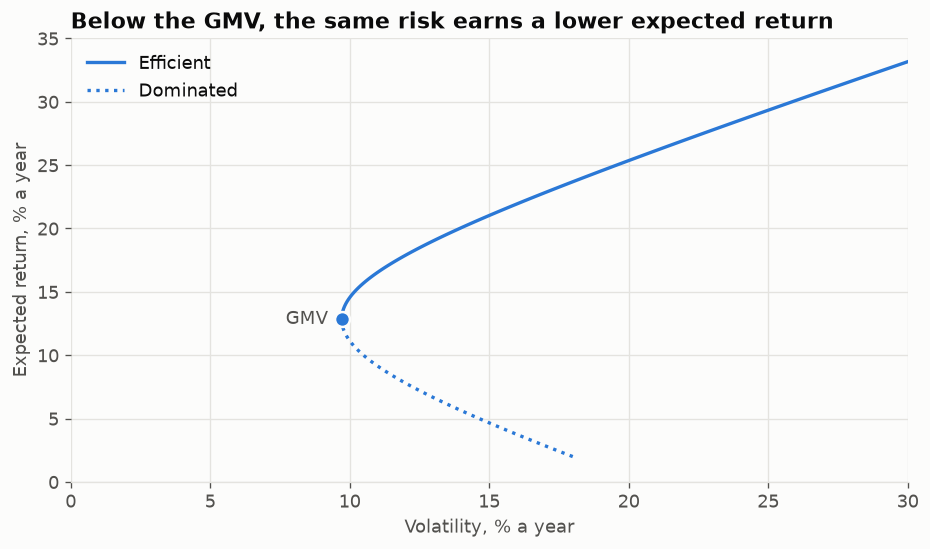

In [2]:
full = fr.Frontier(prac_mean, prac_cov)
efficient = full.curve(full.gmv_return, 0.34)
dominated = full.curve(0.02, full.gmv_return)
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.grid(axis="x")
ax.plot(efficient["volatility"] * 100, efficient["expected_return"] * 100, color=SERIES_1,
        label="Efficient")
ax.plot(dominated["volatility"] * 100, dominated["expected_return"] * 100, color=SERIES_1,
        linestyle=":", label="Dominated")
ax.scatter(full.gmv_volatility * 100, full.gmv_return * 100, s=80, color=SERIES_1,
           edgecolor=SURFACE, linewidth=1.5, zorder=4)
ax.text(full.gmv_volatility * 100 - 0.5, full.gmv_return * 100, "GMV", ha="right", va="center",
        color=MUTED)
ax.set_xlim(0, 30)
ax.set_ylim(0, 35)
ax.set_xlabel("Volatility, % a year")
ax.set_ylabel("Expected return, % a year")
ax.set_title("Below the GMV, the same risk earns a lower expected return")
ax.legend(frameon=False, loc="upper left")
fig.savefig(FIGURES / "04_efficient_part.png")
plt.show()

## 2. What limits do to the frontier

Constraints can only shrink the set of possible portfolios, so on paper each one pushes the frontier
to the right or cuts it shorter.

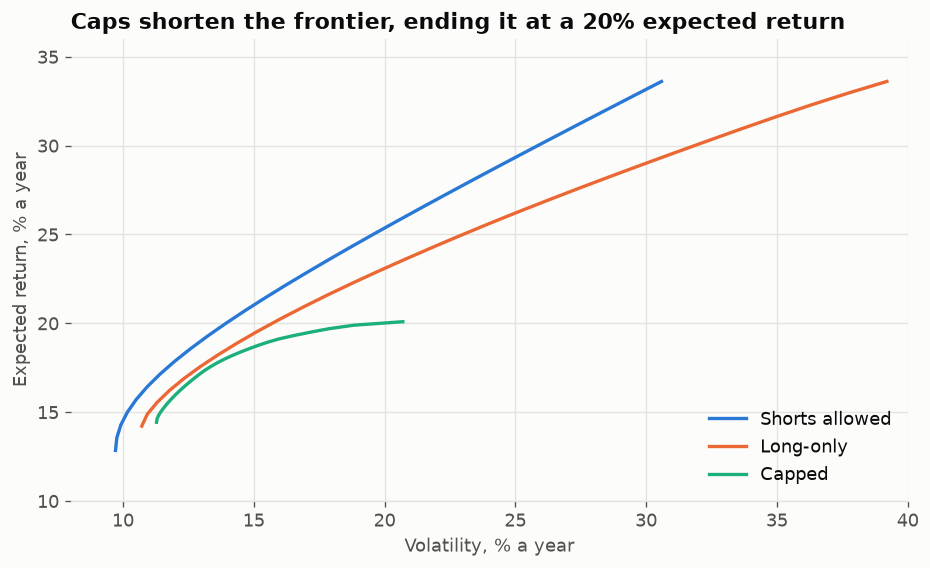

,inputs,rules,gmv_return,gmv_vol,mid_return,mid_vol,mid_sharpe,top_return,mid_effective_stocks
0,Textbook,Shorts allowed,0.142,0.109,0.307,0.173,1.401,0.471,3.062
1,Textbook,Long-only,0.165,0.115,0.318,0.199,1.278,0.471,3.452
2,Textbook,Capped,0.166,0.119,0.206,0.129,1.105,0.245,11.873
3,Textbook,Capped + sector,0.166,0.119,0.206,0.129,1.105,0.245,11.873
4,Practical,Shorts allowed,0.128,0.097,0.232,0.175,0.965,0.336,2.806
5,Practical,Long-only,0.142,0.107,0.239,0.213,0.825,0.336,4.206
6,Practical,Capped,0.144,0.113,0.173,0.130,0.835,0.201,11.464
7,Practical,Capped + sector,0.144,0.113,0.173,0.130,0.835,0.201,11.464


In [3]:
frontiers = {name: fr.efficient_frontier(prac_mean, prac_cov, rule, points=30)
             for name, rule in RULES.items() if name != "Capped + sector"}
fig, ax = plt.subplots(figsize=(9, 5))
ax.grid(axis="x")
for (name, (summary, _)), color in zip(frontiers.items(), [SERIES_1, SERIES_2, SERIES_3]):
    ax.plot(summary["volatility"] * 100, summary["expected_return"] * 100, color=color, label=name)
ax.set_xlim(8, 40)
ax.set_ylim(10, 36)
ax.set_xlabel("Volatility, % a year")
ax.set_ylabel("Expected return, % a year")
ax.set_title("Caps shorten the frontier, ending it at a 20% expected return")
ax.legend(frameon=False, loc="lower right")
fig.savefig(FIGURES / "04_constrained_frontiers.png")
plt.show()

rows = []
for inputs, mean, cov in [("Textbook", text_mean, text_cov), ("Practical", prac_mean, prac_cov)]:
    for name, rule in RULES.items():
        low = fr.solve_min_variance(mean, cov, None, rule)
        mid = fr.frontier_point(mean, cov, rule, 0.5)
        low_return, low_vol = fr.portfolio_stats(low, mean, cov)
        mid_return, mid_vol = fr.portfolio_stats(mid, mean, cov)
        rows.append({"inputs": inputs, "rules": name, "gmv_return": low_return, "gmv_vol": low_vol,
                     "mid_return": mid_return, "mid_vol": mid_vol,
                     "mid_sharpe": (mid_return - RISK_FREE) / mid_vol,
                     "top_return": fr.highest_return(mean, rule),
                     "mid_effective_stocks": fr.effective_stocks(mid)})
pd.DataFrame(rows).round(3)

`mid` is the portfolio halfway up each frontier by expected return. `effective_stocks` measures
concentration: 4 means the portfolio is as concentrated as 4 equal positions.

**The 30% sector limit changes almost nothing.** The 10% stock cap already spreads the portfolio
widely enough that sector limits rarely apply at these points.

### The cost on paper

At the same expected return, how much extra volatility do the limits add?

In [4]:
rows = {}
for target in [0.15, 0.17, 0.19]:
    rows[f"{target:.0%} target"] = {
        name: fr.portfolio_stats(fr.solve_min_variance(prac_mean, prac_cov, target, rule),
                                 prac_mean, prac_cov)[1]
        for name, rule in RULES.items()}
(pd.DataFrame(rows).T * 100).round(2)

,Shorts allowed,Long-only,Capped,Capped + sector
15% target,10.17,10.99,11.44,11.44
17% target,11.31,12.43,12.81,12.81
19% target,12.97,14.50,15.68,15.68


## 3. What the portfolios hold

These charts show how holdings change moving up each frontier. Long-only portfolios concentrate
quickly as the return target rises, ending in a single stock. The cap prevents that.

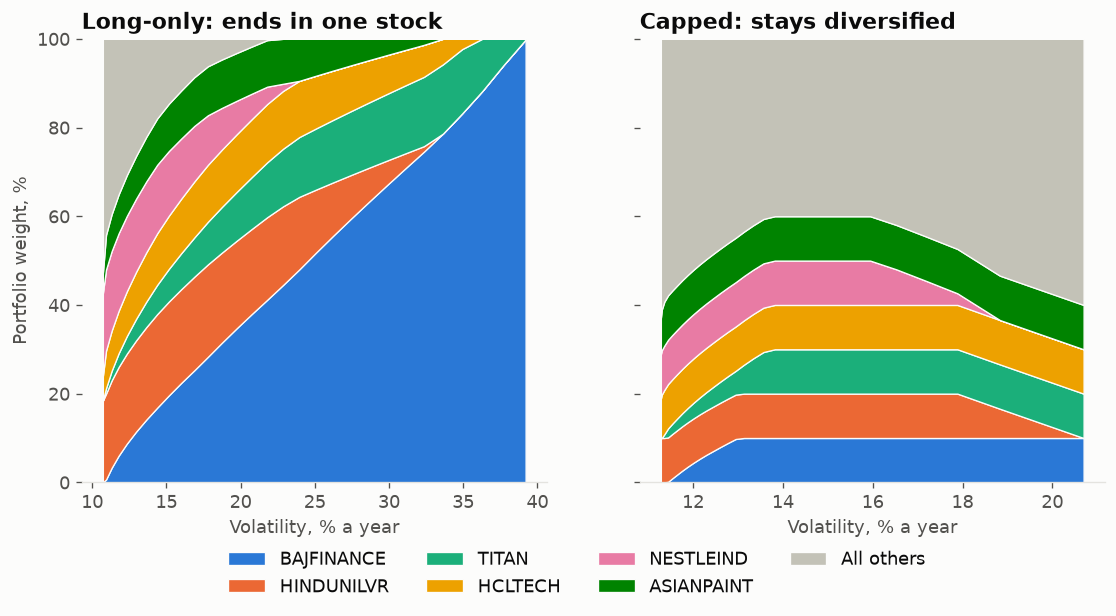

In [5]:
def composition(ax, weights, summary, title, names):
    other = weights.drop(columns=names).sum(axis=1)
    stacked = [weights[name] * 100 for name in names] + [other * 100]
    ax.stackplot(summary["volatility"] * 100, stacked, colors=PALETTE[:len(names)] + ["#c3c2b7"],
                 labels=names + ["All others"], edgecolor=SURFACE, linewidth=0.8)
    ax.set_title(title)
    ax.set_ylim(0, 100)
    ax.set_xlabel("Volatility, % a year")
    ax.grid(False)


long_summary, long_weights = frontiers["Long-only"]
cap_summary, cap_weights = frontiers["Capped"]
names = long_weights.mean().sort_values(ascending=False).head(6).index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)
composition(axes[0], long_weights, long_summary, "Long-only: ends in one stock", names)
composition(axes[1], cap_weights, cap_summary, "Capped: stays diversified", names)
axes[0].set_ylabel("Portfolio weight, %")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, ncols=4, loc="upper center", bbox_to_anchor=(0.5, 0.02))
fig.savefig(FIGURES / "04_composition.png")
plt.show()

## 4. Do limits stabilize the weights?

This repeats the Stage 3 bootstrap on the mid-frontier portfolio, with 200 resamples.

In [6]:
def stability(inputs, rule):
    draws = fr.bootstrap_weights(excess, inputs, RISK_FREE, draws=200,
                                 builder=lambda m, c: fr.frontier_point(m, c, rule, 0.5))
    return {"average_weight_sd": draws.std().mean(),
            "largest_weight_sd": draws.std().max(),
            "average_effective_stocks": draws.apply(fr.effective_stocks, axis=1).mean()}


pd.DataFrame({f"{inputs}, {name}": stability(fn, RULES[name])
              for inputs, fn in [("Textbook", textbook), ("Practical", practical)]
              for name in ["Shorts allowed", "Long-only", "Capped"]}).T.round(3)

,average_weight_sd,largest_weight_sd,average_effective_stocks
"Textbook, Shorts allowed",0.105,0.170,2.474
"Textbook, Long-only",0.054,0.132,4.641
"Textbook, Capped",0.026,0.039,11.715
"Practical, Shorts allowed",0.069,0.114,3.386
"Practical, Long-only",0.050,0.112,4.953
"Practical, Capped",0.023,0.039,11.736


## 5. Do limits help in practice?

Stage 3 used a single split. This is a fuller walk-forward test: each year, fit on the previous
window, build the portfolio, hold it for 12 months, then repeat. Each rule is tried at the bottom
(`low`) and middle (`mid`) of its frontier, with equal weight and the market as benchmarks.

Returns are in excess of T-bills, with no trading costs yet. Portfolios are reset to their target
weights monthly. **The holdout is still untouched.**

In [7]:
def strategy(inputs, rule, position):
    def build(train):
        monthly_mean, monthly_cov = inputs(train)
        mean, cov = fr.annualize(monthly_mean, monthly_cov, RISK_FREE)
        return fr.frontier_point(mean, cov, rule, position)
    return build


strategies = {
    f"{label} {name} {tag}": strategy(fn, RULES[name], position)
    for label, fn in [("Textbook", textbook), ("Practical", practical)]
    for name in ["Shorts allowed", "Long-only", "Capped"]
    for tag, position in [("low", 0), ("mid", 0.5)]
}
strategies["Equal weight"] = lambda train: pd.Series(1 / len(stocks), index=stocks)
strategies["Market proxy"] = lambda train: pd.Series({market: 1.0})

long_window = backtest.run(excess, strategies, window=60, step=12)
short_window = backtest.run(excess, strategies, window=36, step=12)
card_60 = backtest.scorecard(long_window)
card_36 = backtest.scorecard(short_window)
print(f"60-month window: {len(long_window.returns)} test months from "
      f"{long_window.returns.index.min():%b %Y}")
card_60.sort_values("sharpe", ascending=False).round(3)

60-month window: 93 test months from Feb 2016


,excess_return,volatility,sharpe,max_drawdown,turnover,largest_position,short_exposure
Equal weight,0.147,0.162,0.907,-0.254,0.000,0.040,0.000
Practical Capped mid,0.134,0.151,0.884,-0.164,0.142,0.100,0.000
Practical Long-only mid,0.187,0.219,0.855,-0.257,0.328,0.329,0.000
Textbook Capped mid,0.131,0.159,0.826,-0.193,0.180,0.100,0.000
Practical Capped low,0.113,0.140,0.805,-0.192,0.117,0.100,0.000
Textbook Long-only mid,0.188,0.239,0.785,-0.311,0.445,0.359,0.000
Textbook Capped low,0.108,0.145,0.745,-0.228,0.166,0.100,0.000
Textbook Long-only low,0.104,0.144,0.723,-0.191,0.282,0.217,0.000
Practical Shorts allowed low,0.099,0.143,0.694,-0.142,0.247,0.180,0.268
Practical Long-only low,0.102,0.148,0.693,-0.170,0.200,0.200,0.000


In [8]:
print(f"36-month window: {len(short_window.returns)} test months from "
      f"{short_window.returns.index.min():%b %Y}")
card_36.sort_values("sharpe", ascending=False).round(3)

36-month window: 117 test months from Feb 2014


,excess_return,volatility,sharpe,max_drawdown,turnover,largest_position,short_exposure
Practical Long-only mid,0.162,0.173,0.938,-0.195,0.475,0.308,0.000
Equal weight,0.141,0.156,0.904,-0.254,0.000,0.040,0.000
Practical Capped mid,0.125,0.145,0.863,-0.168,0.238,0.100,0.000
Textbook Long-only mid,0.153,0.178,0.861,-0.181,0.504,0.333,0.000
Practical Capped low,0.106,0.133,0.796,-0.169,0.167,0.100,0.000
Textbook Capped low,0.107,0.135,0.790,-0.188,0.228,0.100,0.000
Textbook Capped mid,0.113,0.145,0.783,-0.159,0.262,0.100,0.000
Textbook Long-only low,0.102,0.144,0.703,-0.206,0.404,0.247,0.000
Practical Shorts allowed low,0.093,0.138,0.675,-0.165,0.330,0.188,0.254
Practical Long-only low,0.095,0.143,0.665,-0.173,0.257,0.212,0.000


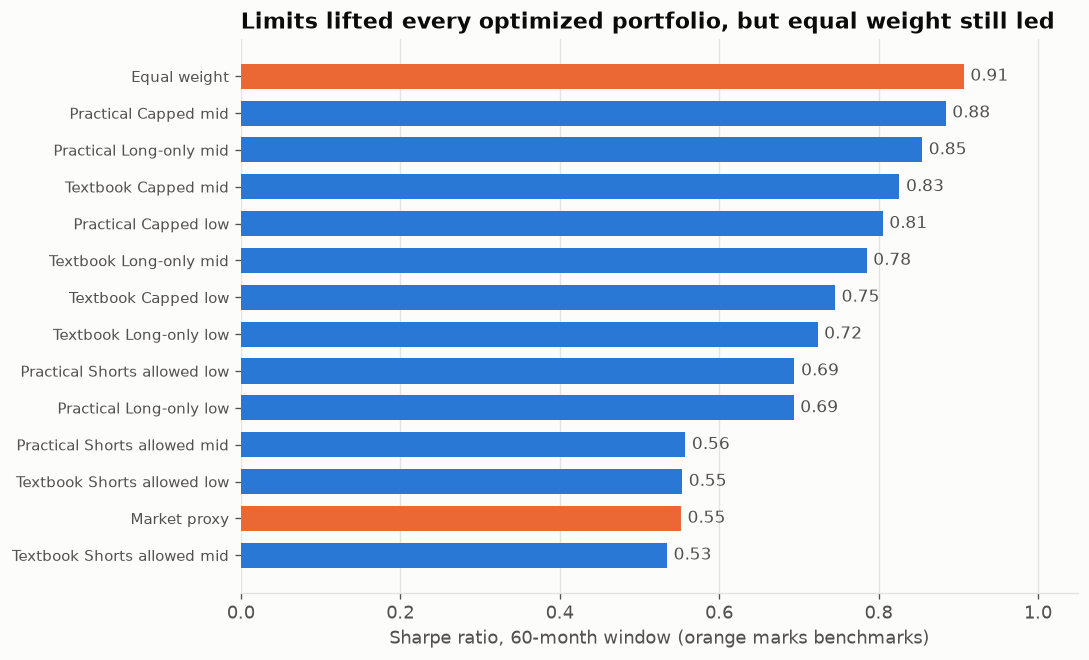

In [9]:
shown = card_60["sharpe"].sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
colors = [SERIES_2 if name in ("Equal weight", "Market proxy") else SERIES_1 for name in shown.index]
bars = ax.barh(shown.index, shown, color=colors, height=0.68)
ax.bar_label(bars, fmt="%.2f", padding=4, color=MUTED, fontsize=10)
ax.tick_params(axis="y", labelsize=9)
ax.set_xlim(0, 1.05)
ax.set_xlabel("Sharpe ratio, 60-month window (orange marks benchmarks)")
ax.set_title("Limits lifted every optimized portfolio, but equal weight still led")
fig.savefig(FIGURES / "04_walk_forward.png")
plt.show()

A rough standard error for a Sharpe ratio over 93 months is about 0.35, so **most of these gaps
are within noise**. The drawdown, turnover and shorting columns are the clearer differences.

## 6. A candidate portfolio

Stage 5 onward will carry this portfolio: **practical inputs, long-only, 10% cap, mid-frontier**. It
isn't a declared winner. It was among the best on both windows, is easy to hold, and stays stable.
The result below uses all estimation months, so it is a description of the method, not a
recommendation to buy these stocks.

In [10]:
candidate = fr.frontier_point(prac_mean, prac_cov, RULES["Capped"], 0.5)
candidate_return, candidate_vol = fr.portfolio_stats(candidate, prac_mean, prac_cov)
held = candidate[candidate > 0.001].sort_values(ascending=False)
print(f"Expected return {candidate_return:.1%}, volatility {candidate_vol:.1%}, "
      f"Sharpe {(candidate_return - RISK_FREE) / candidate_vol:.2f}, "
      f"{len(held)} stocks, {fr.effective_stocks(candidate):.1f} effective stocks")
pd.DataFrame({"weight": held, "sector": sectors[held.index]}).round(3)

Expected return 17.3%, volatility 13.0%, Sharpe 0.83, 13 stocks, 11.5 effective stocks


,weight,sector
HINDUNILVR,0.100,FMCG
NESTLEIND,0.100,FMCG
TCS,0.100,Information Technology
HCLTECH,0.100,Information Technology
ASIANPAINT,0.100,Consumer
BAJFINANCE,0.100,Financial Services
DRREDDY,0.098,Healthcare
ITC,0.077,FMCG
SUNPHARMA,0.069,Healthcare
TITAN,0.058,Consumer


In [11]:
by_sector = candidate.groupby(sectors).sum().sort_values(ascending=False)
equal = pd.Series(1 / len(stocks), index=stocks)
equal_return, equal_vol = fr.portfolio_stats(equal, prac_mean, prac_cov)
summary, _ = frontiers["Capped"]
reachable = np.interp(equal_vol, summary["volatility"], summary["expected_return"])
print(f"Equal weight on practical inputs: return {equal_return:.1%}, volatility {equal_vol:.1%}")
print(f"Capped frontier at that volatility: return {reachable:.1%}")
by_sector.round(3).to_frame("weight")

Equal weight on practical inputs: return 16.6%, volatility 16.1%
Capped frontier at that volatility: return 19.2%


,weight
sector,
FMCG,0.277
Information Technology,0.249
Healthcare,0.167
Consumer,0.158
Financial Services,0.126
Cement,0.023
Automobile,0.000
Telecom,0.000
Energy,0.000


## Stage 4 conclusions

1. **Only the upper frontier matters:** portfolios below the GMV are dominated.
2. **Limits have a real cost on paper:** the capped frontier has higher risk and stops near a 20%
   expected return, far below the top of the unconstrained curve.
3. **That cost does not appear in practice:** in the walk-forward test, capped portfolios beat their
   shorting versions on Sharpe ratio in every comparison. Constraints work as protection against
   estimation error, so they are a feature rather than a sacrifice here.
4. **Shorting performed worst:** portfolios with shorts had the largest turnover and, with a 36-month
   window, large losses. The textbook inputs did especially badly.
5. **Long-only without caps concentrates heavily:** mid-frontier portfolios act like 3–4 stocks.
6. **The sector cap is redundant here:** the 10% stock cap already does the job for this universe.
7. **Equal weight is still hard to beat:** optimized portfolios matched it roughly on Sharpe ratio,
   with lower drawdowns on the capped versions. Survivorship helps equal weight here, so Stage 10 has
   to settle this.

These results exclude trading costs and taxes. Stage 10 adds them.